## Neural network tuning on the Imagenette dataset

In this notebook we are going to fine tune the `ResNet-18` model, present in `torchvision`, in order to try and get better results for image classification on the Imagenette dataset.

### Prerequisites

In [ ]:
%pip install albumentations

In [7]:
import os

import torch

import torch.nn as nn

import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from torchvision import models

from torchvision.io import read_image

import albumentations as albu



import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns



from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay



from functools import partial, reduce

from typing import TypeVar, List, Tuple, Optional, Callable



import warnings

### Types



In this section, we are defining a series of type sysnonyms, constants and functions for later use.

In [2]:
# TYPES

T = TypeVar('T')



String = str

Bool = bool



# CONSTANTS



# FUNCTIONS

def compose(*funcs):

    return lambda x: reduce(lambda acc, f: f(acc), reversed(funcs), x)



def init(l : List[T]) -> T:

    return l[:-1]



def last(l : List[T]) -> T:

    return l[-1]

### Fetching the data

In [11]:
def get_data_location():
    if os.getcwd() == '/kaggle/working':
        
        return '../input/imagenette-dataset/dataset/'
    
    else:
        
        return 'dataset/'


def read_data() -> Tuple[pd.DataFrame, pd.DataFrame]:

    DATA_LOCATION = get_data_location()
    
    FILE = DATA_LOCATION + 'noisy_imagenette.csv'

    data = pd.read_csv(FILE).drop(columns=['noisy_labels_1', 'noisy_labels_5', 'noisy_labels_25', 'noisy_labels_50'])

    resize = albu.Compose([

        albu.Resize(160, 160),

        albu.ToFloat(max_value=255.0)

    ])

    

    def process_image(path):

        image = read_image(get_data_location() + path).numpy()  # Convert to NumPy array

        if image.shape[0] == 1:  # If grayscale, convert to RGB

            image = np.repeat(image, 3, axis=0)

        image = np.transpose(image, (1, 2, 0))  # Change shape from (C, H, W) to (H, W, C)

        image = resize(image = image)['image']  # Apply albumentations resize and normalize

        image = np.transpose(image, (2, 0, 1))  # Change shape back to (C, H, W)

        image = torch.tensor(image).to(torch.float32)  # Convert back to PyTorch tensor

        return image

    

    data['path'] = data['path'].map(process_image)

    

    X1 = data.groupby(data.is_valid).get_group(False); X = X1.sample(n = len(X1)).reset_index(drop = True).drop(columns = ['is_valid'])

    y1 = data.groupby(data.is_valid).get_group(True); y = y1.sample(n = len(y1)).reset_index(drop = True).drop(columns = ['is_valid'])

    return X, y



def get_dataloaders() -> Tuple[DataLoader, DataLoader]:

    train, test = read_data()

    encoder = LabelEncoder()

    encoder.fit(train['noisy_labels_0'])

    train['noisy_labels_0'] = encoder.transform(train['noisy_labels_0'])

    test['noisy_labels_0'] = encoder.transform(test['noisy_labels_0'])

    X = DataLoader(list(zip(train['path'], train['noisy_labels_0'])), shuffle = True, batch_size = 16)

    y = DataLoader(list(zip(test['path'], test['noisy_labels_0'])), batch_size = 16)

    return X, y

In [12]:
train_data, test_data = get_dataloaders()

### The actual model

In [17]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights = 'IMAGENET1K_V1')

model.fc = nn.Linear(model.fc.in_features, 10)

model = model.to(device)



def fit(model, epochs : int = 20, train_data : DataLoader = train_data) -> None:

    optimizer = torch.optim.SGD(model.parameters(), lr = 2e-5, momentum = 0.9)

    criterion = nn.CrossEntropyLoss()



    model.train()



    for epoch in range(epochs):

        losses = []



        for batch_no, input_data in enumerate(train_data):

            optimizer.zero_grad()

            x, y = input_data

            x = x.clone().detach().to(device)

            y = y.clone().detach().to(device).long()



            output = model.forward(x)

            loss = criterion(output, y)

            loss.backward()

            losses.append(loss.item())



            optimizer.step()



        print('Epoch %d | Loss %6.2f' % (epoch + 1, sum(losses) / len(losses)))



def predict(model, data_loader: DataLoader):

    model.eval()

    all_preds = []

    all_labels = []

    with torch.no_grad():

        for inputs, labels in data_loader:

            inputs = inputs.to(device)

            outputs = model.forward(inputs)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy().tolist())

            all_labels.extend(labels.cpu().numpy().tolist())

    

    all_preds = np.array(all_preds, dtype = int)

    all_labels = np.array(all_labels, dtype = int)



    # Print statistics

    print("Classification_report:\n")

    print(classification_report(all_labels, all_preds, digits = 4))

    print("Confusion matrix:\n")

    matrix = confusion_matrix(all_labels, all_preds)

    disp = ConfusionMatrixDisplay(matrix)

    disp.plot()

    plt.show()



def fit_predict(model, epochs : int, train_data : DataLoader, test_data : DataLoader) -> Tuple[List[float], List[float], List[float], List[float]]:

    optimizer = torch.optim.SGD(model.parameters(), lr = 2e-5, momentum = 0.9)

    criterion = nn.CrossEntropyLoss()



    train_losses = []

    train_accuracies = []

    test_losses = []

    test_accuracies = []

    for epoch in range(epochs):

        model.train()

        losses = []



        correct = 0

        total = 0

        for batch_no, input_data in enumerate(train_data):

            optimizer.zero_grad()

            x, y = input_data

            x = x.clone().detach().to(device)

            y = y.clone().detach().to(device).long()



            output = model.forward(x)

            loss = criterion(output, y)

            loss.backward()

            losses.append(loss.item())

            optimizer.step()



            _, predicted = torch.max(output, 1)

            correct += (predicted == y).sum().item()

            total += y.size(0)



        train_losses.append(sum(losses) / len(losses))

        train_accuracies.append(correct / total)

        

        model.eval()

        test_losses_1 = []



        correct = 0

        total = 0

        with torch.no_grad():

            for t in test_data:

                x = t[0].clone().detach().to(device)

                y = torch.tensor(t[1]).to(device).long()

                raw_output = model.forward(x).float()

                loss = criterion(raw_output, y)

                test_losses_1.append(loss.item())

                _, output = torch.max(raw_output, 1)

                correct += (output == y).sum().item()

                total += y.size(0)



        test_losses.append(sum(test_losses_1) / len(test_losses_1))

        test_accuracies.append(correct / total)



    # plot the train and test losses

    plt.figure(figsize = (15, 9))

    plt.plot(train_losses, label = 'train_loss')

    plt.plot(test_losses, label = 'test_loss')

    plt.legend()

    plt.show() 

    plt.clf()

    

    # plot the train and test accuracies

    plt.figure(figsize = (15, 9))

    plt.plot(train_accuracies, label = 'train_accuracy')

    plt.plot(test_accuracies, label = 'test_accuracy')

    plt.legend()

    plt.show()
    
    
    return train_losses, train_accuracies, test_losses, test_accuracies

### Functions that run the experiments

Epoch 1 | Loss   1.84
Epoch 2 | Loss   1.04
Epoch 3 | Loss   0.71
Epoch 4 | Loss   0.56
Epoch 5 | Loss   0.47
Epoch 6 | Loss   0.41
Epoch 7 | Loss   0.37
Epoch 8 | Loss   0.35
Epoch 9 | Loss   0.32
Epoch 10 | Loss   0.30
Epoch 11 | Loss   0.29
Epoch 12 | Loss   0.27
Epoch 13 | Loss   0.26
Epoch 14 | Loss   0.25
Epoch 15 | Loss   0.25
Epoch 16 | Loss   0.23
Epoch 17 | Loss   0.22
Epoch 18 | Loss   0.22
Epoch 19 | Loss   0.22
Epoch 20 | Loss   0.20
Classification_report:

              precision    recall  f1-score   support

           0     0.9646    0.9845    0.9744       387
           1     0.9974    0.9772    0.9872       395
           2     0.9570    0.9356    0.9462       357
           3     0.8649    0.9456    0.9035       386
           4     0.9480    0.9804    0.9639       409
           5     0.9570    0.9594    0.9582       394
           6     0.9415    0.9512    0.9463       389
           7     0.9547    0.8544    0.9018       419
           8     0.9650    0.9674    0

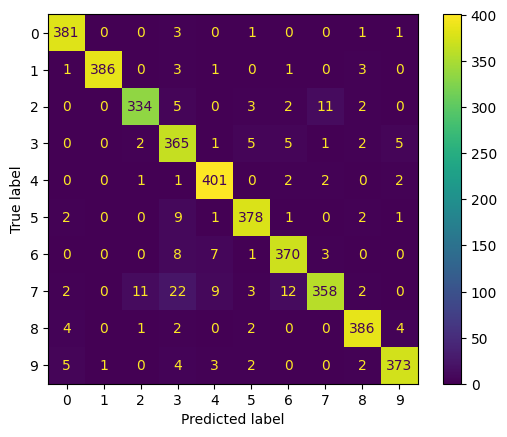

In [16]:
fit(model, epochs = 20, train_data = train_data)

predict(model, test_data)

/tmp/ipykernel_30/759351009.py:189: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(t[1]).to(device).long()


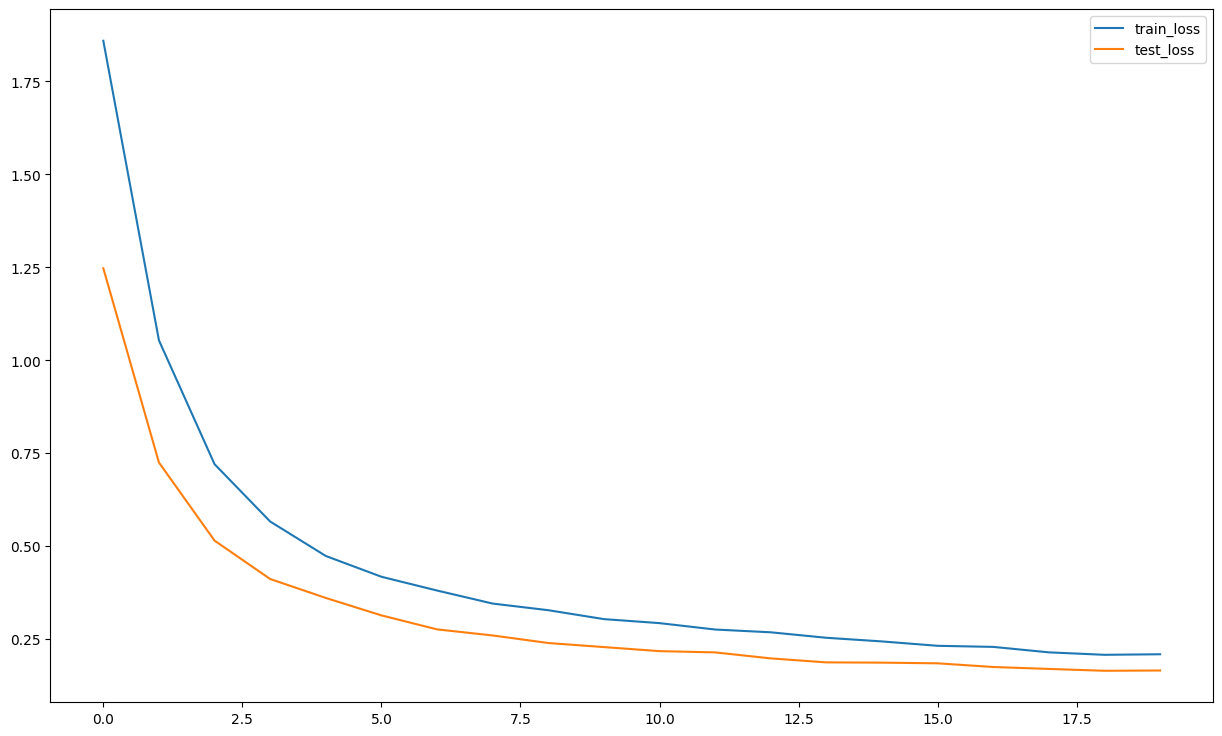

<Figure size 640x480 with 0 Axes>

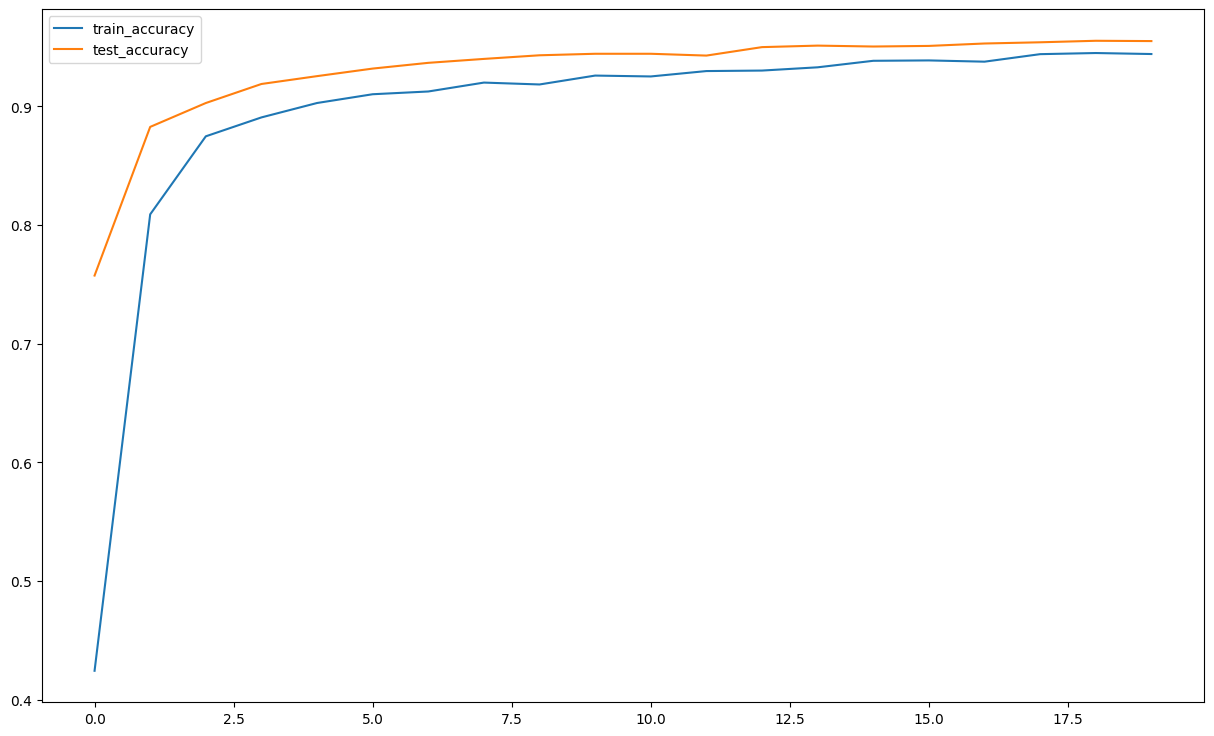

([1.859537903722879,
  1.053678373932033,
  0.7205056378970275,
  0.5662790440979439,
  0.4735754883621593,
  0.41769221683057983,
  0.3806292580667178,
  0.3455503042535605,
  0.3277042815210046,
  0.30372577713726945,
  0.2929274044565957,
  0.2757248538231628,
  0.2682668421530744,
  0.2535094981069198,
  0.24371980024954756,
  0.23193331601450573,
  0.22900755297568803,
  0.21431459059208832,
  0.20771561599827396,
  0.20918627442301227],
 [0.42422642306473757,
  0.8090611469004119,
  0.8748547893124934,
  0.8908015629950364,
  0.9029464568592248,
  0.9103390009504699,
  0.9126623719505755,
  0.9201605238145527,
  0.9185764072235717,
  0.9260745590875489,
  0.9253353046784243,
  0.9298764389059034,
  0.9302988699968318,
  0.9330446720878657,
  0.9385362762699334,
  0.9388530995881297,
  0.9377970218608089,
  0.9441334882247333,
  0.945083958179322,
  0.9442390959974654],
 [1.2476751821312477,
  0.7250648013702253,
  0.5149160825866994,
  0.41163253850810894,
  0.36068830617923076,


In [18]:
fit_predict(model, 20, train_data, test_data)